In [ ]:
#E-Commerce Sales Analysis
## 1. Project Overview

# This project focuses on analyzing e-commerce sales data to understand business performance, customer purchasing behavior, and product trends.

# Using Python and data analysis libraries, the project explores revenue trends, top-performing products and categories, regional sales performance, customer segmentation, retention, and order status patterns.

# The objective is to identify meaningful business insights and provide data-driven recommendations to improve sales performance, customer retention, and overall business decision-making.

In [111]:
#imported libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [112]:
## 3. Load Dataset
df=pd.read_csv("ecommerce_raw_data.csv")

In [113]:
## 4. Data Cleaning
df.head(5)

,order_id,order_date,customer_id,product,category,quantity,unit_price,discount_pct,region,payment_method,order_status
0,ORD100623,2025-10-23,CUST00180,Mechanical Keyboard,Accessories,1,2499,0.00,East,Debit Card,Delivered
1,ORD100785,2025-02-21,CUST00477,Laptop Sleeve,Accessories,3,999,0.15,North,Cash on Delivery,Delivered
2,ORD101887,2024-05-20,CUST00545,Power Bank,Electronics,4,1899,0.00,Central,Credit Card,Delivered
3,ORD101485,2024-02-08,CUST00622,Power Bank,Electronics,4,1899,0.05,East,Credit Card,Delivered
4,ORD103150,2024-01-24,CUST00428,Monitor,Electronics,4,12499,0.10,Central,Credit Card,Delivered


In [4]:
df.shape

(3508, 11)

In [5]:
df.size

38588

In [6]:
df.columns

Index(['order_id', 'order_date', 'customer_id', 'product', 'category',
       'quantity', 'unit_price', 'discount_pct', 'region', 'payment_method',
       'order_status'],
      dtype='object')

In [7]:
df.info

<bound method DataFrame.info of        order_id  order_date customer_id              product     category  \
0     ORD100623  2025-10-23   CUST00180  Mechanical Keyboard  Accessories   
1     ORD100785  2025-02-21   CUST00477        Laptop Sleeve  Accessories   
2     ORD101887  2024-05-20   CUST00545           Power Bank  Electronics   
3     ORD101485  2024-02-08   CUST00622           Power Bank  Electronics   
4     ORD103150  2024-01-24   CUST00428              Monitor  Electronics   
...         ...         ...         ...                  ...          ...   
3503  ORD100049  2024-12-10   CUST00232               Webcam        Video   
3504  ORD100773  2024-05-17   CUST00827         Laptop Stand       Office   
3505  ORD101849  2025-11-30   CUST00110        Laptop Sleeve  Accessories   
3506  ORD101232  2024-08-19   CUST00628    Bluetooth Speaker        Audio   
3507  ORD103018  2025-01-09   CUST00708           Power Bank  Electronics   

      quantity  unit_price  discount_pct   

In [8]:
df.dtypes

order_id           object
order_date         object
customer_id        object
product            object
category           object
quantity            int64
unit_price          int64
discount_pct      float64
region             object
payment_method     object
order_status       object
dtype: object

In [9]:
df.isnull().sum()

order_id           0
order_date         0
customer_id       14
product            0
category           0
quantity           0
unit_price         0
discount_pct       0
region             8
payment_method     6
order_status       0
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(8)

In [11]:
df.describe()

,quantity,unit_price,discount_pct
count,3508.000000,3508.000000,3508.000000
mean,2.487742,2597.232611,0.060946
std,1.124484,2715.852828,0.061570
min,1.000000,799.000000,0.000000
25%,1.000000,1399.000000,0.000000
50%,2.000000,1899.000000,0.050000
75%,4.000000,2799.000000,0.100000
max,4.000000,12499.000000,0.200000


In [12]:
df.order_id.duplicated().sum()

np.int64(8)

In [13]:
(df.quantity<=0).sum()

np.int64(0)

In [14]:
(df["unit_price"]<=0).sum()

np.int64(0)

In [15]:
((df["discount_pct"]<0 )| (df["discount_pct"]>1)).sum()

np.int64(0)

In [16]:
df[df["order_id"].duplicated(keep=False)].sort_values("order_id")

,order_id,order_date,customer_id,product,category,quantity,unit_price,discount_pct,region,payment_method,order_status
997,ORD100498,2025-10-27,CUST00670,Wireless Mouse,Accessories,2,799,0.05,East,UPI,Delivered
1889,ORD100498,2025-10-27,CUST00670,Wireless Mouse,Accessories,2,799,0.05,East,UPI,Delivered
380,ORD100649,2024-10-05,CUST00162,Power Bank,Electronics,1,1899,0.15,North,Credit Card,Delivered
1608,ORD100649,2024-10-05,CUST00162,Power Bank,Electronics,1,1899,0.15,North,Credit Card,Delivered
2807,ORD100655,2025-02-08,CUST00238,Headphones,Audio,1,2999,0.00,North,Net Banking,Delivered
3350,ORD100655,2025-02-08,CUST00238,Headphones,Audio,1,2999,0.00,North,Net Banking,Delivered
1834,ORD101336,2024-04-06,CUST00368,Headphones,Audio,1,2999,0.00,North,UPI,Delivered
2296,ORD101336,2024-04-06,CUST00368,Headphones,Audio,1,2999,0.00,North,UPI,Delivered
734,ORD101462,2024-07-03,CUST00013,Power Bank,Electronics,3,1899,0.15,South,Net Banking,Delivered
2454,ORD101462,2024-07-03,CUST00013,Power Bank,Electronics,3,1899,0.15,South,Net Banking,Delivered


In [17]:
df["order_id"].value_counts().loc[lambda x: x > 1]

order_id
ORD100649    2
ORD102878    2
ORD103408    2
ORD101462    2
ORD102708    2
ORD100498    2
ORD101336    2
ORD100655    2
Name: count, dtype: int64

In [18]:
df[df["order_id"].duplicated(keep=False)].groupby("order_id").nunique()

,order_date,customer_id,product,category,quantity,unit_price,discount_pct,region,payment_method,order_status
order_id,,,,,,,,,,
ORD100498,1,1,1,1,1,1,1,1,1,1
ORD100649,1,1,1,1,1,1,1,1,1,1
ORD100655,1,1,1,1,1,1,1,1,1,1
ORD101336,1,1,1,1,1,1,1,1,1,1
ORD101462,1,1,1,1,1,1,1,1,1,1
ORD102708,1,1,1,1,1,1,1,1,1,1
ORD102878,1,1,1,1,1,1,1,1,1,1
ORD103408,1,1,1,1,1,1,1,1,1,1


In [19]:
df = df.drop_duplicates()

In [20]:
df.duplicated().sum()

np.int64(0)

In [21]:
df.isnull().sum()

order_id           0
order_date         0
customer_id       14
product            0
category           0
quantity           0
unit_price         0
discount_pct       0
region             8
payment_method     6
order_status       0
dtype: int64

In [22]:
df.isnull().sum().sum()

np.int64(28)

In [23]:
(df.isnull().sum()/len(df)*100),round(2)

(order_id          0.000000
 order_date        0.000000
 customer_id       0.400000
 product           0.000000
 category          0.000000
 quantity          0.000000
 unit_price        0.000000
 discount_pct      0.000000
 region            0.228571
 payment_method    0.171429
 order_status      0.000000
 dtype: float64,
 2)

In [24]:
df[df["customer_id"].isnull()]

,order_id,order_date,customer_id,product,category,quantity,unit_price,discount_pct,region,payment_method,order_status
390,ORD101387,2024-10-08,NaN,Headphones,Audio,1,2999,0.10,Central,Credit Card,Delivered
441,ORD100910,2025-01-23,NaN,Webcam,Video,2,2299,0.10,East,UPI,Delivered
1122,ORD102877,2024-02-28,NaN,Webcam,Video,4,2299,0.00,North,Cash on Delivery,Delivered
1123,ORD100678,2024-06-28,NaN,Wireless Mouse,Accessories,3,799,0.20,South,Debit Card,Delivered
1149,ORD101775,2025-08-27,NaN,Webcam,Video,3,2299,0.05,Central,Credit Card,Delivered
1459,ORD100113,2025-09-18,NaN,Power Bank,Electronics,3,1899,0.00,South,Credit Card,Delivered
1566,ORD100268,2024-09-07,NaN,Headphones,Audio,2,2999,0.00,North,Debit Card,Delivered
2115,ORD100151,2025-03-29,NaN,Bluetooth Speaker,Audio,3,2799,0.00,West,Debit Card,Returned
2213,ORD101108,2024-06-28,NaN,USB-C Hub,Accessories,4,1799,0.10,West,UPI,Delivered
2458,ORD100464,2025-06-13,NaN,Laptop Sleeve,Accessories,1,999,0.10,East,UPI,Delivered


In [25]:
df[df["region"].isnull()]

,order_id,order_date,customer_id,product,category,quantity,unit_price,discount_pct,region,payment_method,order_status
140,ORD101737,2024-02-25,CUST00032,Bluetooth Speaker,Audio,3,2799,0.05,NaN,Credit Card,Processing
316,ORD100298,2025-12-22,CUST00899,Monitor,Electronics,3,12499,0.15,NaN,Credit Card,Delivered
791,ORD100066,2025-04-12,CUST00429,Laptop Sleeve,Accessories,1,999,0.00,NaN,UPI,Delivered
1326,ORD101909,2024-07-09,CUST00574,Laptop Stand,Office,3,1399,0.00,NaN,Credit Card,Delivered
1858,ORD101964,2025-04-23,CUST00498,Webcam,Video,3,2299,0.00,NaN,Credit Card,Delivered
2917,ORD102893,2024-04-16,CUST00731,Mechanical Keyboard,Accessories,3,2499,0.00,NaN,UPI,Returned
3220,ORD101695,2024-04-23,CUST00071,Bluetooth Speaker,Audio,2,2799,0.20,NaN,Cash on Delivery,Delivered
3310,ORD102275,2024-06-04,CUST00679,Power Bank,Electronics,4,1899,0.00,NaN,Net Banking,Delivered


In [26]:
df[df["payment_method"].isnull()]

,order_id,order_date,customer_id,product,category,quantity,unit_price,discount_pct,region,payment_method,order_status
202,ORD100481,2025-10-28,CUST00547,Bluetooth Speaker,Audio,1,2799,0.05,West,NaN,Delivered
349,ORD100039,2024-02-11,CUST00354,Laptop Stand,Office,3,1399,0.15,North,NaN,Delivered
488,ORD103039,2024-05-24,CUST00640,Headphones,Audio,2,2999,0.05,East,NaN,Delivered
609,ORD100371,2025-05-02,CUST00087,Power Bank,Electronics,2,1899,0.00,North,NaN,Delivered
1774,ORD100893,2025-01-25,CUST00667,Laptop Stand,Office,1,1399,0.00,North,NaN,Returned
3210,ORD103202,2024-10-06,CUST00887,Mechanical Keyboard,Accessories,2,2499,0.00,West,NaN,Delivered


In [27]:
df["region"]=df["region"].fillna("Unknown")
df["payment_method"]=df["payment_method"].fillna("Unknown")

C:\Users\Akshi\AppData\Local\Temp\ipykernel_32840\4225749695.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["region"]=df["region"].fillna("Unknown")
C:\Users\Akshi\AppData\Local\Temp\ipykernel_32840\4225749695.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["payment_method"]=df["payment_method"].fillna("Unknown")


In [28]:
df.isnull().sum()

order_id           0
order_date         0
customer_id       14
product            0
category           0
quantity           0
unit_price         0
discount_pct       0
region             0
payment_method     0
order_status       0
dtype: int64

In [29]:
print("rows: ",df.shape[0])
print("columns: ",df.shape[1])
print("exact duplicate rows:",df.duplicated().sum())
print("unique costumer ids:", df["customer_id"].nunique())

rows:  3500
columns:  11
exact duplicate rows: 0
unique costumer ids: 879


In [30]:
df["order_date"]=pd.to_datetime(df["order_date"])

C:\Users\Akshi\AppData\Local\Temp\ipykernel_32840\2186700018.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["order_date"]=pd.to_datetime(df["order_date"])


In [31]:
df["order_date"].dtype

dtype('<M8[ns]')

In [32]:
## 5. Exploratory Data Analysis
df["Revenue"]=df["quantity"]*df["unit_price"]*(1-df["discount_pct"])

C:\Users\Akshi\AppData\Local\Temp\ipykernel_32840\372656172.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Revenue"]=df["quantity"]*df["unit_price"]*(1-df["discount_pct"])


In [33]:
df["Revenue"]

0        2499.00
1        2547.45
2        7596.00
3        7216.20
4       44996.40
          ...   
3503     6552.15
3504     4197.00
3505      999.00
3506     5318.10
3507     7216.20
Name: Revenue, Length: 3500, dtype: float64

In [34]:
df.head()

,order_id,order_date,customer_id,product,category,quantity,unit_price,discount_pct,region,payment_method,order_status,Revenue
0,ORD100623,2025-10-23,CUST00180,Mechanical Keyboard,Accessories,1,2499,0.00,East,Debit Card,Delivered,2499.00
1,ORD100785,2025-02-21,CUST00477,Laptop Sleeve,Accessories,3,999,0.15,North,Cash on Delivery,Delivered,2547.45
2,ORD101887,2024-05-20,CUST00545,Power Bank,Electronics,4,1899,0.00,Central,Credit Card,Delivered,7596.00
3,ORD101485,2024-02-08,CUST00622,Power Bank,Electronics,4,1899,0.05,East,Credit Card,Delivered,7216.20
4,ORD103150,2024-01-24,CUST00428,Monitor,Electronics,4,12499,0.10,Central,Credit Card,Delivered,44996.40


In [35]:
print("Total Revenue across all orders: ",df["Revenue"].sum())
print("Average Revenue per order: ",df["Revenue"].mean())
print("highest revenue generated by a single order :",df["Revenue"].max())

Total Revenue across all orders:  21386109.85
Average Revenue per order:  6110.3171
highest revenue generated by a single order : 49996.0


In [36]:
df.groupby("product")["Revenue"].sum().sort_values(ascending=False)

product
Monitor                6823829.05
Headphones             3030039.65
Mechanical Keyboard    2228233.35
Bluetooth Speaker      1993867.65
Webcam                 1585160.50
USB-C Hub              1480307.15
Power Bank             1431276.30
Laptop Stand           1116192.15
Wireless Mouse         1025876.05
Laptop Sleeve           671328.00
Name: Revenue, dtype: float64

In [37]:
df.groupby("category")["Revenue"].sum().sort_values(ascending=False)

category
Electronics    8255105.35
Accessories    5405744.55
Audio          5023907.30
Video          1585160.50
Office         1116192.15
Name: Revenue, dtype: float64

In [38]:
Rev_category=df.groupby("category")["Revenue"].sum()

In [39]:
Rev_category

category
Accessories    5405744.55
Audio          5023907.30
Electronics    8255105.35
Office         1116192.15
Video          1585160.50
Name: Revenue, dtype: float64

In [40]:
category_contribution=((Rev_category/df["Revenue"].sum()) *100).sort_values(ascending=False)

In [41]:
print(category_contribution)

category
Electronics    38.600313
Accessories    25.276895
Audio          23.491450
Video           7.412103
Office          5.219239
Name: Revenue, dtype: float64


In [42]:
df["order_month"]=df["order_date"].dt.to_period("M")

C:\Users\Akshi\AppData\Local\Temp\ipykernel_32840\3344064971.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["order_month"]=df["order_date"].dt.to_period("M")


In [43]:
df["order_month"]

0       2025-10
1       2025-02
2       2024-05
3       2024-02
4       2024-01
         ...   
3503    2024-12
3504    2024-05
3505    2025-11
3506    2024-08
3507    2025-01
Name: order_month, Length: 3500, dtype: period[M]

In [44]:
Rev_month=df.groupby("order_month")["Revenue"].sum()

In [45]:
print(Rev_month)

order_month
2024-01     986125.95
2024-02     928459.70
2024-03     961510.85
2024-04    1081132.35
2024-05     923878.25
2024-06     996110.75
2024-07     866901.60
2024-08     798792.75
2024-09     984593.40
2024-10     697507.45
2024-11     672360.70
2024-12    1137376.25
2025-01     978970.00
2025-02     934551.95
2025-03     861179.70
2025-04     829490.90
2025-05     814309.00
2025-06     774418.70
2025-07     840185.75
2025-08     896650.50
2025-09     872044.65
2025-10     851168.65
2025-11     780598.70
2025-12     917791.35
Freq: M, Name: Revenue, dtype: float64


In [46]:
yearly_rev=df.groupby(df["order_date"].dt.to_period("Y"))["Revenue"].sum()

In [47]:
print(yearly_rev)

order_date
2024    11034750.00
2025    10351359.85
Freq: Y-DEC, Name: Revenue, dtype: float64


In [48]:
yoy_growth=((yearly_rev[0]-yearly_rev[1])/yearly_rev[0]) *100

C:\Users\Akshi\AppData\Local\Temp\ipykernel_32840\1314278860.py:1: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  yoy_growth=((yearly_rev[0]-yearly_rev[1])/yearly_rev[0]) *100


In [49]:
yoy_growth

np.float64(6.19307324588233)

In [50]:
yearly_revenue = df.groupby(df["order_date"].dt.year)["Revenue"].sum()

yearly_orders = df.groupby(df["order_date"].dt.year)["order_id"].nunique()

print("Yearly revenue:")
print(yearly_revenue)

print("\nYearly orders:")
print(yearly_orders)

Yearly revenue:
order_date
2024    11034750.00
2025    10351359.85
Name: Revenue, dtype: float64

Yearly orders:
order_date
2024    1761
2025    1739
Name: order_id, dtype: int64


In [51]:
aov = yearly_revenue / yearly_orders
print("\nAverage order value:")
print(aov)


Average order value:
order_date
2024    6266.183986
2025    5952.478350
dtype: float64


In [52]:
product_status = df.groupby(["product", "order_status"])["order_id"].count().unstack(fill_value=0)

product_status

order_status,Cancelled,Delivered,Processing,Returned
product,,,,
Bluetooth Speaker,18,256,11,18
Headphones,23,379,14,27
Laptop Sleeve,14,266,11,13
Laptop Stand,17,298,12,17
Mechanical Keyboard,13,339,8,18
Monitor,11,198,7,12
Power Bank,11,280,14,17
USB-C Hub,12,305,8,17
Webcam,14,253,8,21


In [53]:
product_status["total_orders"] = product_status.sum(axis=1)

product_status["return_rate"] = (
    product_status["Returned"] / product_status["total_orders"] * 100
)

product_status["cancellation_rate"] = (
    product_status["Cancelled"] / product_status["total_orders"] * 100
)

product_status[["return_rate", "cancellation_rate"]].sort_values(
    by="return_rate", ascending=False
)

order_status,return_rate,cancellation_rate
product,,
Webcam,7.094595,4.729730
Headphones,6.094808,5.191874
Bluetooth Speaker,5.940594,5.940594
Power Bank,5.279503,3.416149
Monitor,5.263158,4.824561
USB-C Hub,4.970760,3.508772
Laptop Stand,4.941860,4.941860
Mechanical Keyboard,4.761905,3.439153
Laptop Sleeve,4.276316,4.605263


In [54]:
category_status = df.groupby(["category", "order_status"])["order_id"].count().unstack(fill_value=0)

category_status

order_status,Cancelled,Delivered,Processing,Returned
category,,,,
Accessories,69,1392,40,63
Audio,41,635,25,45
Electronics,22,478,21,29
Office,17,298,12,17
Video,14,253,8,21


In [55]:
category_status["total_orders"] = category_status.sum(axis=1)

category_status["return_rate"] = (
    category_status["Returned"] / category_status["total_orders"] * 100
)

category_status["cancellation_rate"] = (
    category_status["Cancelled"] / category_status["total_orders"] * 100
)

category_status[["return_rate", "cancellation_rate"]].sort_values(
    by="return_rate", ascending=False
)

order_status,return_rate,cancellation_rate
category,,
Video,7.094595,4.729730
Audio,6.032172,5.495979
Electronics,5.272727,4.000000
Office,4.941860,4.941860
Accessories,4.028133,4.411765


In [56]:
rev_reg=df.groupby("region")["Revenue"].sum().sort_values(ascending=False)
print(rev_reg)

region
Central    4478263.80
West       4322143.10
South      4221358.70
North      4191830.15
East       4101000.10
Unknown      71514.00
Name: Revenue, dtype: float64


In [57]:
regional_revenue=df.groupby("region")["Revenue"].sum()/df["Revenue"].sum() *100
print(regional_revenue.round(2).sort_values(ascending=False))

region
Central    20.94
West       20.21
South      19.74
North      19.60
East       19.18
Unknown     0.33
Name: Revenue, dtype: float64


In [58]:
order_count_by_status=df.groupby("order_status")["order_id"].count().sort_values(ascending=False)
print(order_count_by_status)

order_status
Delivered     3056
Returned       175
Cancelled      163
Processing     106
Name: order_id, dtype: int64


In [59]:
contribution_status=df.groupby("order_status")["order_id"].count()/df["order_status"].count() *100
print(contribution_status.sort_values(ascending=False))

order_status
Delivered     87.314286
Returned       5.000000
Cancelled      4.657143
Processing     3.028571
Name: order_id, dtype: float64


In [60]:
rev_status=df.groupby("order_status")["Revenue"].sum()
print(rev_status.sort_values(ascending=False))

order_status
Delivered     18548676.20
Returned       1120396.75
Cancelled      1006836.30
Processing      710200.60
Name: Revenue, dtype: float64


In [61]:
status_contribution=rev_status/df["Revenue"].sum() *100
print(status_contribution.sort_values(ascending=False))

order_status
Delivered     86.732353
Returned       5.238899
Cancelled      4.707898
Processing     3.320850
Name: Revenue, dtype: float64


In [62]:
print(df[df["order_status"]=="Delivered"]["Revenue"].sum())

18548676.2


In [63]:
delivered_rev=df[df["order_status"]=="Delivered"].groupby("region")["Revenue"].sum()
print(delivered_rev.sort_values(ascending=False))

region
West       3846692.80
South      3840610.10
Central    3773870.35
North      3580791.85
East       3450671.25
Unknown      56039.85
Name: Revenue, dtype: float64


In [64]:
rev_prod=df[df["order_status"]=="Delivered"].groupby("product")["Revenue"].sum().head()

In [65]:
quantity_prod=df[df["order_status"]=="Delivered"].groupby("product")["quantity"].sum().head()

In [66]:
(rev_prod/quantity_prod).sort_values(ascending=False)

product
Headphones             2815.910066
Bluetooth Speaker      2642.689336
Mechanical Keyboard    2351.974028
Laptop Stand           1309.561911
Laptop Sleeve           934.414968
dtype: float64

In [67]:
df[df["order_status"]=="Delivered"].groupby("order_month")["Revenue"].sum().sort_index()

order_month
2024-01     882354.55
2024-02     797377.70
2024-03     786839.20
2024-04     875377.45
2024-05     857655.85
2024-06     821186.00
2024-07     682320.50
2024-08     681125.75
2024-09     852540.00
2024-10     584073.40
2024-11     570947.80
2024-12    1043219.20
2025-01     861884.75
2025-02     835289.80
2025-03     784072.15
2025-04     734227.05
2025-05     695690.10
2025-06     696467.45
2025-07     714220.95
2025-08     812138.25
2025-09     769650.95
2025-10     738604.55
2025-11     624149.55
2025-12     847263.25
Freq: M, Name: Revenue, dtype: float64

In [68]:
print(df[df["order_status"]=="Delivered"].groupby(df["order_date"].dt.year)["Revenue"].sum().sort_index())
rev_by_year_delivered=df[df["order_status"]=="Delivered"].groupby(df["order_date"].dt.year)["Revenue"].sum()

order_date
2024    9435017.4
2025    9113658.8
Name: Revenue, dtype: float64


In [69]:
percentage_change_revenue_by_year=(rev_by_year_delivered[2024]-rev_by_year_delivered[2025])/rev_by_year_delivered[2024] *100
print(percentage_change_revenue_by_year)

3.406020215712582


In [70]:
delivered_order_per_year=df[df["order_status"]=="Delivered"].groupby(df["order_date"].dt.year)["order_id"].count()

In [71]:
per_change_in_del_order_in_year=(delivered_order_per_year[2025]-delivered_order_per_year[2024])/delivered_order_per_year[2024] *100
print(per_change_in_del_order_in_year)

-1.4294996751137101


In [72]:
avg_rev_per_del_order=rev_by_year_delivered/delivered_order_per_year
print(avg_rev_per_del_order)

order_date
2024    6130.615595
2025    6007.685432
dtype: float64


In [73]:
df[df["order_status"]=="Delivered"].groupby("product")["discount_pct"].mean().sort_values(ascending=False)

product
USB-C Hub              0.066393
Laptop Sleeve          0.063534
Webcam                 0.061858
Wireless Mouse         0.061618
Headphones             0.061609
Laptop Stand           0.061577
Mechanical Keyboard    0.061357
Power Bank             0.060536
Bluetooth Speaker      0.056836
Monitor                0.055556
Name: discount_pct, dtype: float64

In [74]:
df.groupby("product")["order_id"].nunique().sort_values(ascending=False)

product
Wireless Mouse         540
Headphones             443
Mechanical Keyboard    378
Laptop Stand           344
USB-C Hub              342
Power Bank             322
Laptop Sleeve          304
Bluetooth Speaker      303
Webcam                 296
Monitor                228
Name: order_id, dtype: int64

In [75]:
delivered_df = df[df["order_status"] == "Delivered"]

product_analysis = delivered_df.groupby("product").agg(
    avg_discount=("discount_pct", "mean"),
    total_revenue=("Revenue", "sum")
)

product_analysis = product_analysis.sort_values(
    "total_revenue", ascending=False
)

print(product_analysis)

                     avg_discount  total_revenue
product                                         
Monitor                  0.055556     5880779.50
Headphones               0.061609     2573741.80
Mechanical Keyboard      0.061357     1996825.95
Bluetooth Speaker        0.056836     1672822.35
Webcam                   0.061858     1376641.20
USB-C Hub                0.066393     1333688.65
Power Bank               0.060536     1235869.20
Laptop Stand             0.061577      973004.50
Wireless Mouse           0.061618      918490.45
Laptop Sleeve            0.063534      586812.60


In [76]:
delivered_df.groupby(["region","category"])["Revenue"].sum().sort_values(ascending=False)

region   category   
West     Electronics    1588185.40
South    Electronics    1551921.10
Central  Electronics    1504299.20
North    Electronics    1278656.80
East     Electronics    1154117.75
West     Accessories    1121091.80
Central  Accessories     990944.80
South    Accessories     948020.65
North    Audio           938359.10
East     Audio           911496.60
North    Accessories     895774.85
South    Audio           881477.05
East     Accessories     878986.55
West     Audio           768397.15
Central  Audio           742355.85
North    Video           305996.90
Central  Video           299559.70
East     Video           293352.40
South    Video           266339.15
Central  Office          236710.80
East     Office          212717.95
West     Video           204496.05
South    Office          192852.15
West     Office          164522.40
North    Office          162004.20
Unknown  Electronics      39468.45
         Video             6897.00
         Audio             4478.40

In [77]:
region_category = delivered_df.groupby(
    ["region", "category"]
)["Revenue"].sum()

top_category_by_region = region_category.groupby(
    level="region"
).idxmax()

print(top_category_by_region)

region
Central    (Central, Electronics)
East          (East, Electronics)
North        (North, Electronics)
South        (South, Electronics)
Unknown    (Unknown, Electronics)
West          (West, Electronics)
Name: Revenue, dtype: object


In [78]:
regional_category_pct = region_category.unstack()
regional_category_pct = (
    regional_category_pct
    .div(regional_category_pct.sum(axis=1), axis=0)
) * 100

print(regional_category_pct)

category  Accessories      Audio  Electronics    Office      Video
region                                                            
Central     26.258051  19.670942    39.860914  6.272362   7.937732
East        25.472915  26.415052    33.446181  6.164538   8.501314
North       25.016111  26.205352    35.708772  4.524256   8.545509
South       24.684116  22.951485    40.408192  5.021394   6.934814
Unknown      1.782660   7.991456    70.429257  7.489313  12.307313
West        29.144303  19.975527    41.287035  4.276983   5.316152


In [79]:
delivered_df.groupby("payment_method")["Revenue"].sum().sort_values(ascending=False)

payment_method
UPI                 3991344.60
Debit Card          3859729.20
Cash on Delivery    3583992.40
Credit Card         3563700.45
Net Banking         3529188.95
Unknown               20720.60
Name: Revenue, dtype: float64

In [80]:
pay_df=delivered_df.groupby("payment_method")["Revenue"].sum()
per_share=(pay_df/df["Revenue"].sum()) *100
print("% contribution of payment method per rev: ", per_share)

% contribution of payment method per rev:  payment_method
Cash on Delivery    16.758506
Credit Card         16.663622
Debit Card          18.047832
Net Banking         16.502248
UPI                 18.663257
Unknown              0.096888
Name: Revenue, dtype: float64


In [81]:
df.groupby("order_status").agg(
    order_count=("order_id","count"),
    total_revenue=("Revenue","sum")
)

,order_count,total_revenue
order_status,,
Cancelled,163,1006836.30
Delivered,3056,18548676.20
Processing,106,710200.60
Returned,175,1120396.75


In [82]:
(df.groupby("order_status")["order_id"].count()/df["order_id"].count())*100

order_status
Cancelled      4.657143
Delivered     87.314286
Processing     3.028571
Returned       5.000000
Name: order_id, dtype: float64

In [83]:
## 6. Customer Analysis
df["customer_id"].nunique()

879

In [84]:
df[df["order_status"]=="Delivered"].groupby("customer_id")["Revenue"].sum().head(10).sort_values(ascending=False)

customer_id
CUST00004    59430.55
CUST00001    35231.65
CUST00008    26856.30
CUST00006    26486.00
CUST00007    23929.55
CUST00002    18900.30
CUST00010    10248.60
CUST00005     8097.30
CUST00003     6772.50
CUST00009     3416.40
Name: Revenue, dtype: float64

In [85]:
#average delivered revenue per unique customer.
arpc=df[df["order_status"]=="Delivered"]["Revenue"].sum()/df["customer_id"].nunique()
print(arpc)

21102.020705346986


In [86]:
df[df["order_status"]=="Delivered"].groupby("customer_id")["order_id"].count().sort_values(ascending=False)

customer_id
CUST00504    11
CUST00143    11
CUST00118    11
CUST00559    10
CUST00044     9
             ..
CUST00843     1
CUST00892     1
CUST00889     1
CUST00028     1
CUST00011     1
Name: order_id, Length: 870, dtype: int64

In [87]:
customer_orders=df[df["order_status"]=="Delivered"].groupby("customer_id")["order_id"].count()
customer_orders[customer_orders > 1].count()

np.int64(773)

In [88]:
rep_cust_rate=(customer_orders[customer_orders > 1].count()/df["customer_id"].nunique())*100
print(rep_cust_rate)

87.94084186575654


In [89]:
customer_revenue=df[df["order_status"]=="Delivered"].groupby("customer_id")["Revenue"].sum()
customer_revenue.quantile([0.25,0.75])

0.25     8899.2
0.75    27375.1
Name: Revenue, dtype: float64

In [110]:
conditions=[customer_revenue<=8899.2,
           customer_revenue<=27375.1]
choices=["low value","medium value"]
customer_segment=np.select(conditions, choices, default="high value")


In [91]:
customer_analysis = pd.DataFrame({
    "total_revenue":customer_revenue,
    "customer_segment": customer_segment
})

customer_analysis.head(10)
customer_analysis["customer_segment"].value_counts()

customer_segment
medium value    434
high value      218
low value       218
Name: count, dtype: int64

In [92]:
customer_analysis.groupby("customer_segment")["total_revenue"].sum()

customer_segment
high value      10101539.20
low value        1153432.60
medium value     7233780.25
Name: total_revenue, dtype: float64

In [93]:
(customer_analysis.groupby("customer_segment")["total_revenue"].sum()/customer_analysis["total_revenue"].sum())*100

customer_segment
high value      54.636133
low value        6.238564
medium value    39.125303
Name: total_revenue, dtype: float64

In [94]:
delivered_df["year"] = delivered_df["order_date"].dt.year

C:\Users\Akshi\AppData\Local\Temp\ipykernel_32840\4138060236.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  delivered_df["year"] = delivered_df["order_date"].dt.year


In [95]:
delivered_df.groupby("customer_id")["year"].nunique()

customer_id
CUST00001    2
CUST00002    2
CUST00003    1
CUST00004    2
CUST00005    1
            ..
CUST00896    2
CUST00897    1
CUST00898    2
CUST00899    1
CUST00900    2
Name: year, Length: 870, dtype: int64

In [96]:
delivered_df.groupby("customer_id")["year"].nunique().value_counts()

year
2    603
1    267
Name: count, dtype: int64

In [114]:
## 7. Customer Retention and Churn
customers_2024 = delivered_df[delivered_df["year"] == 2024]["customer_id"].nunique()

retained_customers = 603

retention_rate = (retained_customers / customers_2024) * 100

print("Customers in 2024:", customers_2024)
print("Retained customers:", retained_customers)
print("Customer retention rate:", retention_rate, "%")

Customers in 2024: 728
Retained customers: 603
Customer retention rate: 82.82967032967034 %


In [98]:
churn_rate = (125 / 728) * 100

print("Customer churn rate:", churn_rate, "%")

Customer churn rate: 17.17032967032967 %


In [115]:
# Data visualization

#monthly revenue summary from delivered_df
monthly_revenue=delivered_df.groupby(delivered_df["order_date"].dt.to_period("M"))["Revenue"].sum()
monthly_revenue

order_date
2024-01     882354.55
2024-02     797377.70
2024-03     786839.20
2024-04     875377.45
2024-05     857655.85
2024-06     821186.00
2024-07     682320.50
2024-08     681125.75
2024-09     852540.00
2024-10     584073.40
2024-11     570947.80
2024-12    1043219.20
2025-01     861884.75
2025-02     835289.80
2025-03     784072.15
2025-04     734227.05
2025-05     695690.10
2025-06     696467.45
2025-07     714220.95
2025-08     812138.25
2025-09     769650.95
2025-10     738604.55
2025-11     624149.55
2025-12     847263.25
Freq: M, Name: Revenue, dtype: float64

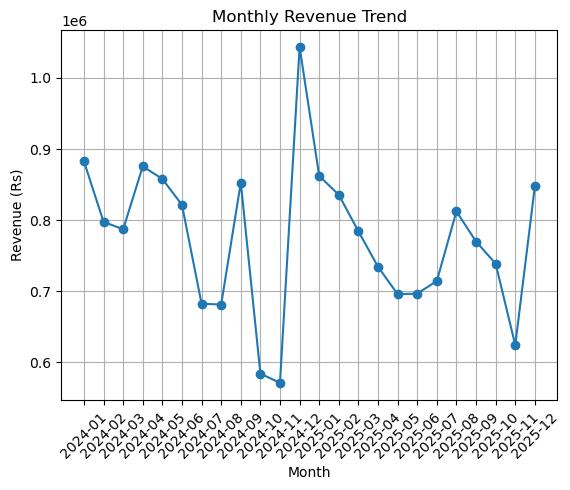

In [116]:


x = monthly_revenue.index.astype(str)
y = monthly_revenue.values

plt.plot(x, y, marker="o")

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (Rs)")
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

In [101]:
product_revenue = delivered_df.groupby("product")["Revenue"].sum().sort_values(ascending=False)

product_revenue

product
Monitor                5880779.50
Headphones             2573741.80
Mechanical Keyboard    1996825.95
Bluetooth Speaker      1672822.35
Webcam                 1376641.20
USB-C Hub              1333688.65
Power Bank             1235869.20
Laptop Stand            973004.50
Wireless Mouse          918490.45
Laptop Sleeve           586812.60
Name: Revenue, dtype: float64

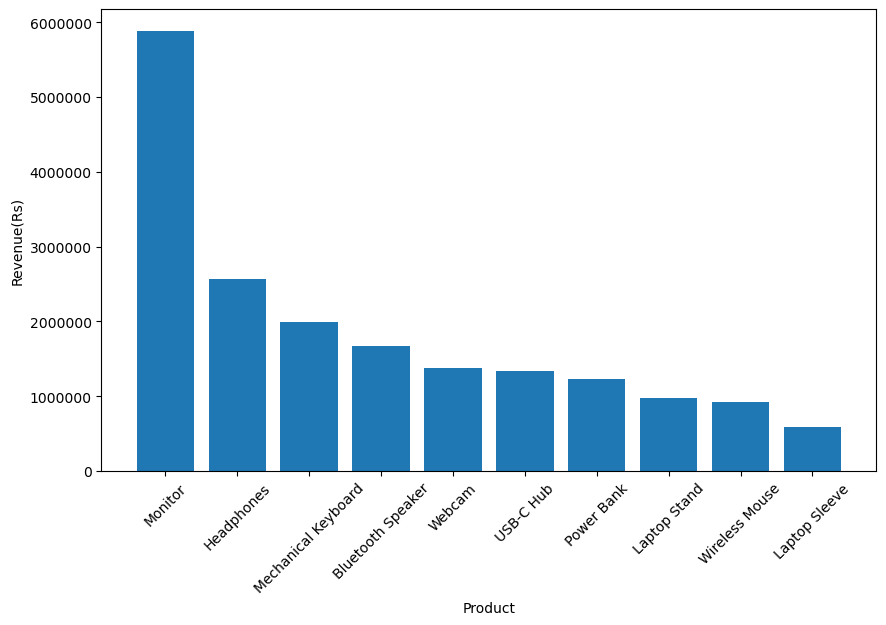

In [102]:
product=product_revenue.index
plt.figure(figsize=(10,6))
rev=product_revenue.values
plt.bar(product,rev)
plt.xlabel("Product")
plt.ylabel("Revenue(Rs)")
plt.xticks(rotation=45)
plt.ticklabel_format(axis="y", style="plain")
plt.show()

In [103]:
region_revenue = delivered_df.groupby("region")["Revenue"].sum().sort_values(ascending=False)

region_revenue

region
West       3846692.80
South      3840610.10
Central    3773870.35
North      3580791.85
East       3450671.25
Unknown      56039.85
Name: Revenue, dtype: float64

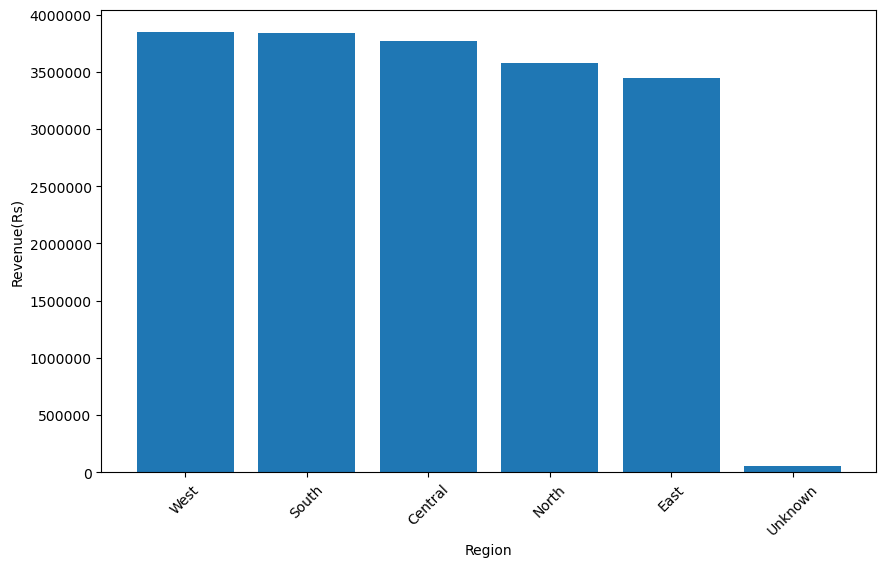

In [104]:

plt.figure(figsize=(10,6))
plt.bar(region_revenue.index,region_revenue.values)
plt.xlabel("Region")
plt.ylabel("Revenue(Rs)")
plt.xticks(rotation=45)
plt.ticklabel_format(axis="y", style="plain")
plt.show()

In [105]:
segment_revenue = customer_analysis.groupby("customer_segment")["total_revenue"].sum().sort_values(ascending=False)

segment_revenue

customer_segment
high value      10101539.20
medium value     7233780.25
low value        1153432.60
Name: total_revenue, dtype: float64

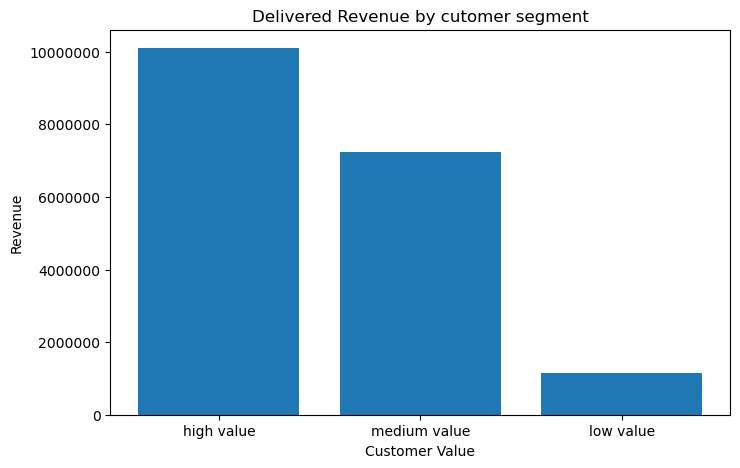

In [106]:
plt.figure(figsize=(8,5))
plt.bar(segment_revenue.index,segment_revenue.values)
plt.title("Delivered Revenue by cutomer segment")
plt.xlabel("Customer Value")
plt.ylabel("Revenue")
plt.ticklabel_format(axis="y", style="plain")
plt.show()


In [107]:
category_revenue = delivered_df.groupby("category")["Revenue"].sum().sort_values(ascending=False)

category_revenue

category
Electronics    7116648.70
Accessories    4835817.65
Audio          4246564.15
Video          1376641.20
Office          973004.50
Name: Revenue, dtype: float64

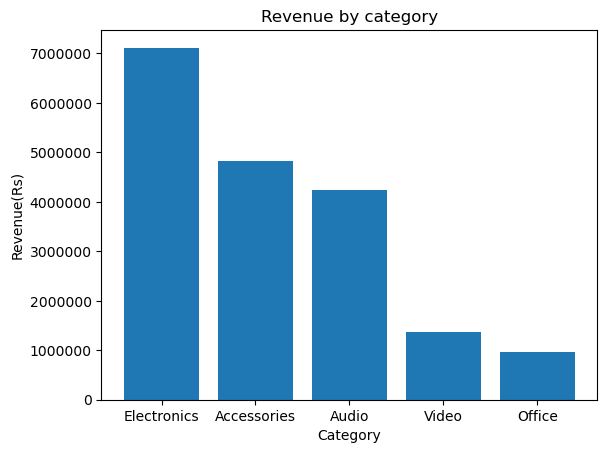

In [108]:
plt.bar(category_revenue.index,category_revenue.values)
plt.title("Revenue by category")
plt.xlabel("Category")
plt.ylabel("Revenue(Rs)")
plt.ticklabel_format(axis="y", style="plain")
plt.show()

In [109]:
## Business Insights and Recommendations
# Insight 1: Customer segmentation
# Finding: High-value customers account for 25% of the customer base but contribute 54.64% of delivered revenue.

# Recommendation: Prioritize retaining high-value customers through personalized offers, loyalty programs, and targeted engagement.
# Insight 2: Customer retention
# Finding: The customer retention rate is 82.83%, while the churn rate is 17.17%.

# Recommendation: Maintain customer engagement and investigate why the 17.17% of customers did not return to make a delivered purchase in 2025.
# Insight 3: Revenue performance
# Finding: Delivered revenue declined by 3.41% in 2025 compared with 2024. The decline coincided with lower delivered order volume and average revenue per order.

# Recommendation: Investigate changes in product sales mix and promote products with strong revenue contribution while exploring ways to increase order volume and average order value.
# Insight 4: Product returns and cancellations
# Finding: Webcam has the highest product return rate at 7.09%, while Bluetooth Speaker has the highest cancellation rate at 5.94%.

# Recommendation: Investigate potential causes of returns and cancellations before increasing promotional activity for these products.
# Insight 5: Category returns and cancellations
# Finding: Video has the highest category return rate at 7.09%, while Audio has the highest cancellation rate at 5.50%.

# Recommendation: Investigate product quality, customer expectations, product descriptions, and delivery-related issues in these categories.

In [ ]:
# ## 10. Conclusion

# This project analyzed e-commerce sales data to evaluate revenue performance, product trends, regional sales, customer behavior, retention, and order status patterns.

# The analysis identified key business trends, including a decline in delivered revenue, strong revenue contribution from high-value customers, and differences in product return and cancellation rates.

# The findings provide useful insights into customer behavior and business performance. The recommendations focus on improving customer retention, investigating product-related issues, and identifying opportunities to improve sales.

# Overall, this project demonstrates how Python-based data analysis can be used to extract meaningful insights from business data and support data-driven decision-making.